RITHANYA.G 24BAD132
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: 60000
Testing images: 10000
Image dimensions: (28, 28)
Training data shape: (60000, 28, 28)


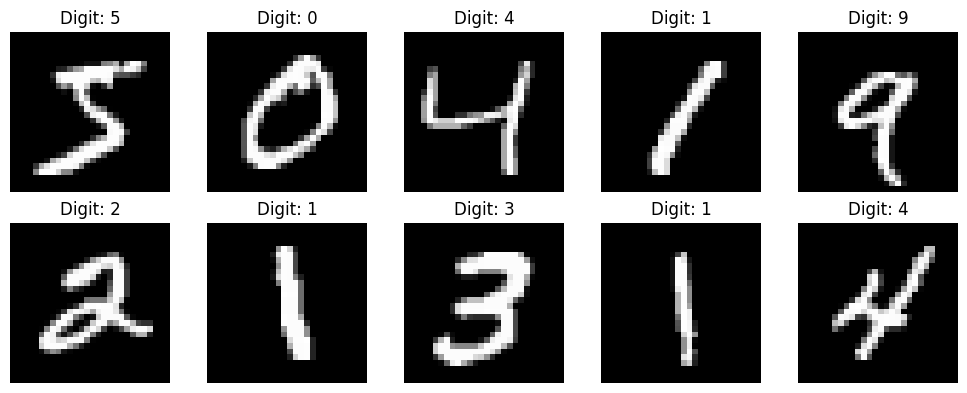

Normalized data shape: (60000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Dataset prepared for batch-wise training.


In [1]:

# PART A: DATASET PREPARATION AND IMAGE PREPROCESSING
# RITHANYA.G 24BAD132

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

print("RITHANYA.G 24BAD132")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape[0])
print("Testing images:", x_test.shape[0])
print("Image dimensions:", x_train.shape[1:])
print("Training data shape:", x_train.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Normalize pixel values from [0, 255] to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Reshape images to (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("Normalized data shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Prepare batches for training
BATCH_SIZE = 128

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset prepared for batch-wise training.")

RITHANYA.G 24BAD132

GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 765,633 (2.92 MB)

 Trainable params: 765,633 (2.92 MB)

 Non-trainable params: 0 (0.00 B)

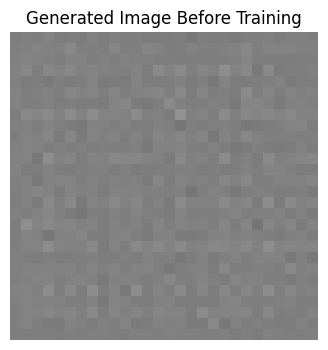

Generator created successfully.
Output image shape: (1, 28, 28, 1)


In [3]:

# PART B: IMPLEMENTING THE GENERATOR
# RITHANYA.G 24BAD132

import tensorflow as tf
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt

print("RITHANYA.G 24BAD132")

LATENT_DIM = 100

noise_input = layers.Input(shape=(LATENT_DIM,))
x = layers.Dense(7 * 7 * 128, activation="relu")(noise_input)
x = layers.Reshape((7, 7, 128))(x)

x = layers.Conv2DTranspose(
    64, kernel_size=4, strides=2,
    padding="same", activation="relu"
)(x)

generated_output = layers.Conv2DTranspose(
    1, kernel_size=4, strides=2,
    padding="same", activation="tanh"
)(x)

generator = Model(
    inputs=noise_input,
    outputs=generated_output,
    name="Generator"
)

print("\nGENERATOR MODEL SUMMARY")
generator.summary()

# Generate an image before training
random_noise = tf.random.normal((1, LATENT_DIM))
generated_image = generator(random_noise, training=False)

plt.figure(figsize=(4, 4))
plt.imshow(
    generated_image[0, :, :, 0].numpy(),
    cmap="gray",
    vmin=-1,
    vmax=1
)
plt.title("Generated Image Before Training")
plt.axis("off")
plt.show()

print("Generator created successfully.")
print("Output image shape:", generated_image.shape)

In [6]:

# PART C: DISCRIMINATOR AND GAN MODEL
# RITHANYA.G 24BAD132

print("RITHANYA.G 24BAD132")

# Keep both networks trainable; Part D will control
# which network gets updated during each training step.
generator.trainable = True
discriminator.trainable = True

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gan_input = layers.Input(shape=(LATENT_DIM,))
gan_output = discriminator(generator(gan_input))
gan = Model(gan_input, gan_output, name="GAN")

gan.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()

print("\nGENERATOR SUMMARY")
generator.summary()

print("\nCOMBINED GAN SUMMARY")
gan.summary()

print("Generator trainable weights:", len(generator.trainable_variables))
print("Discriminator trainable weights:", len(discriminator.trainable_variables))

RITHANYA.G 24BAD132

DISCRIMINATOR SUMMARY


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Functional)          │ (None, 28, 28, 1)      │       765,633 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Functional)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 904,194 (3.45 MB)

 Trainable params: 904,194 (3.45 MB)

 Non-trainable params: 0 (0.00 B)

Generator trainable weights: 6
Discriminator trainable weights: 6


In [2]:

# RITHANYA.G 24BAD132

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

print("RITHANYA.G 24BAD132")
print("TensorFlow version:", tf.__version__)
print("Imports completed successfully.")

RITHANYA.G 24BAD132
TensorFlow version: 2.21.0
Imports completed successfully.


In [6]:

# GAN MODEL SETUP
# RITHANYA.G 24BAD132

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist

print("RITHANYA.G 24BAD132")

LATENT_DIM = 100
BATCH_SIZE = 128

# Load and preprocess MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# Build Generator
noise_input = layers.Input(shape=(LATENT_DIM,))
x = layers.Dense(7 * 7 * 128, activation="relu")(noise_input)
x = layers.Reshape((7, 7, 128))(x)
x = layers.Conv2DTranspose(
    64, 4, strides=2, padding="same", activation="relu"
)(x)
generated_output = layers.Conv2DTranspose(
    1, 4, strides=2, padding="same", activation="tanh"
)(x)
generator = Model(noise_input, generated_output, name="Generator")

# Build Discriminator
image_input = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(64, 4, strides=2, padding="same")(image_input)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Flatten()(x)
prediction = layers.Dense(1, activation="sigmoid")(x)
discriminator = Model(image_input, prediction, name="Discriminator")

print("Generator created:", generator.output_shape)
print("Discriminator created:", discriminator.output_shape)
print("Training batches:", 60000 // BATCH_SIZE)
print("Setup completed successfully.")

RITHANYA.G 24BAD132
Generator created: (None, 28, 28, 1)
Discriminator created: (None, 1)
Training batches: 468
Setup completed successfully.


RITHANYA.G 24BAD132
Epoch 1/10 - Discriminator Loss: 0.3490 - Generator Loss: 2.7692


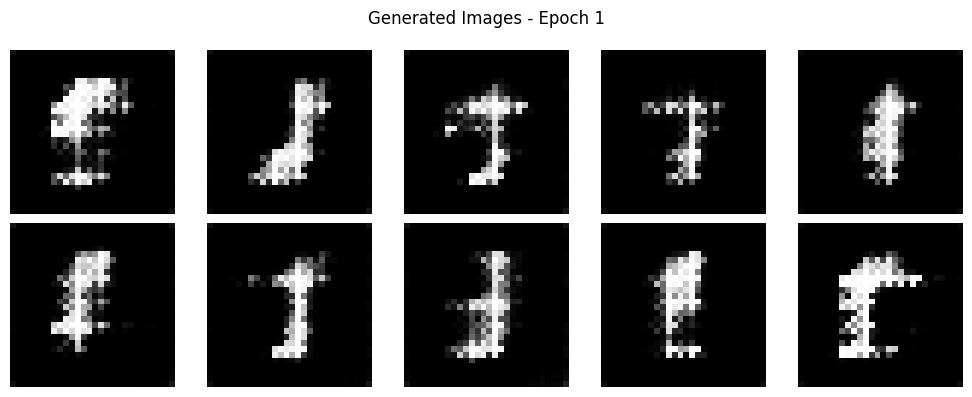

Epoch 2/10 - Discriminator Loss: 0.7507 - Generator Loss: 1.9083


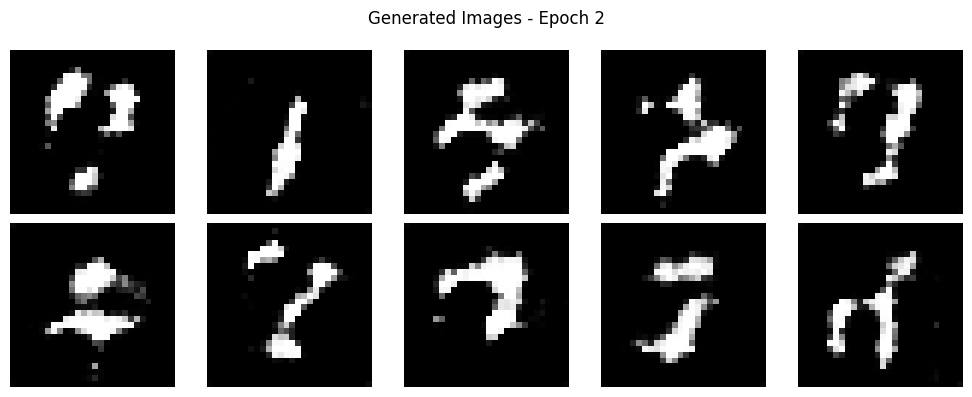

Epoch 3/10 - Discriminator Loss: 0.8791 - Generator Loss: 1.5193
Epoch 4/10 - Discriminator Loss: 0.9389 - Generator Loss: 1.2980


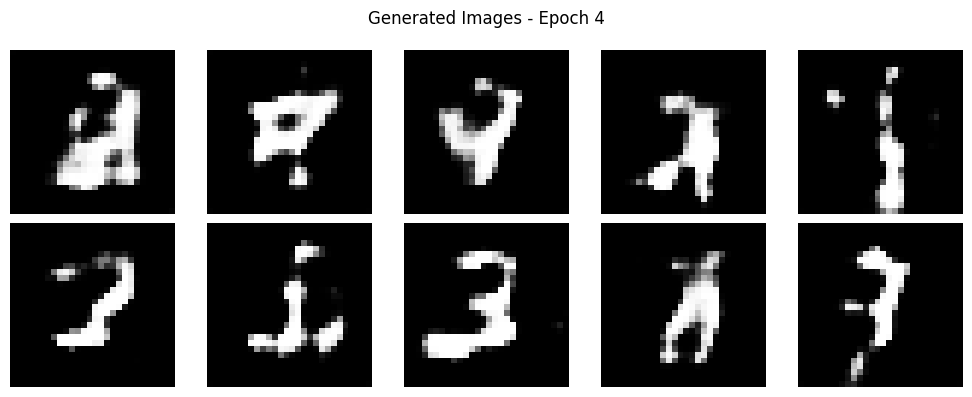

Epoch 5/10 - Discriminator Loss: 0.9142 - Generator Loss: 1.3242
Epoch 6/10 - Discriminator Loss: 1.0105 - Generator Loss: 1.2466


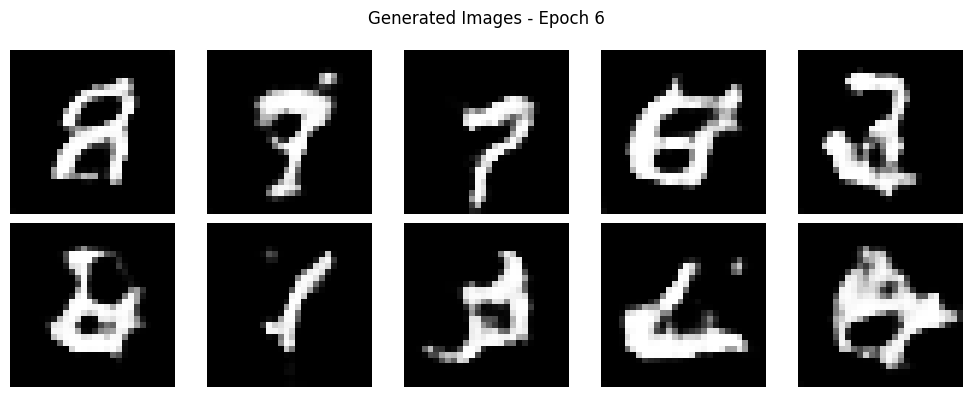

Epoch 7/10 - Discriminator Loss: 1.0644 - Generator Loss: 1.1724
Epoch 8/10 - Discriminator Loss: 1.0872 - Generator Loss: 1.1211


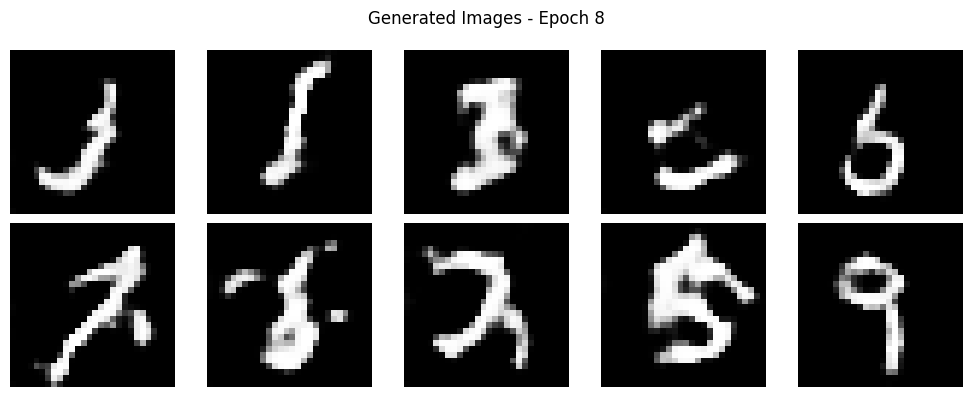

Epoch 9/10 - Discriminator Loss: 1.1135 - Generator Loss: 1.0885
Epoch 10/10 - Discriminator Loss: 1.1348 - Generator Loss: 1.0685


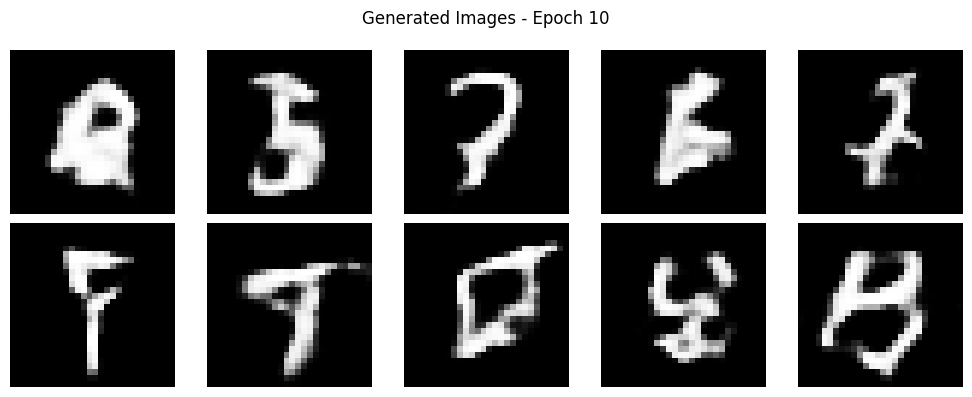

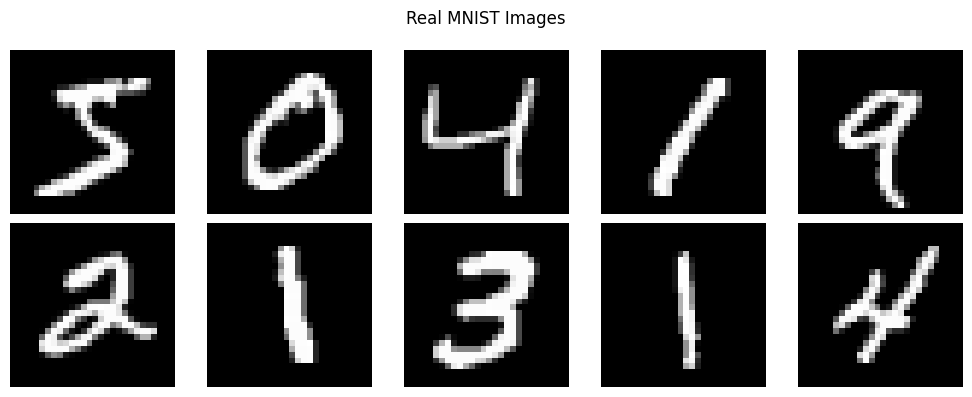

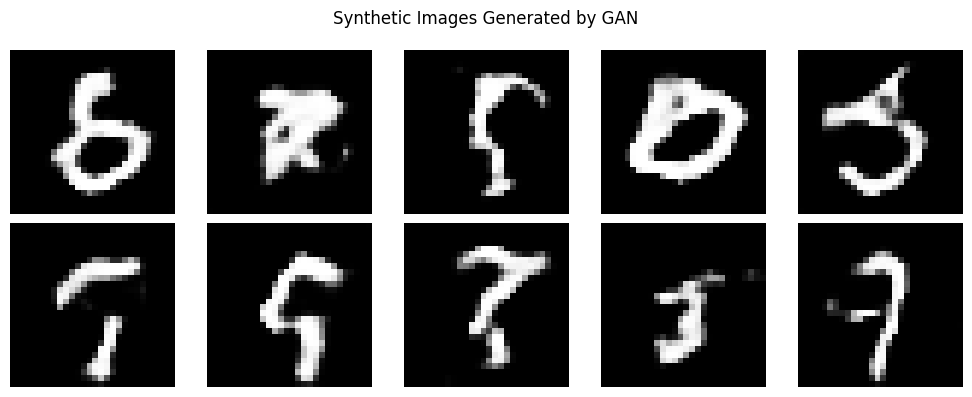

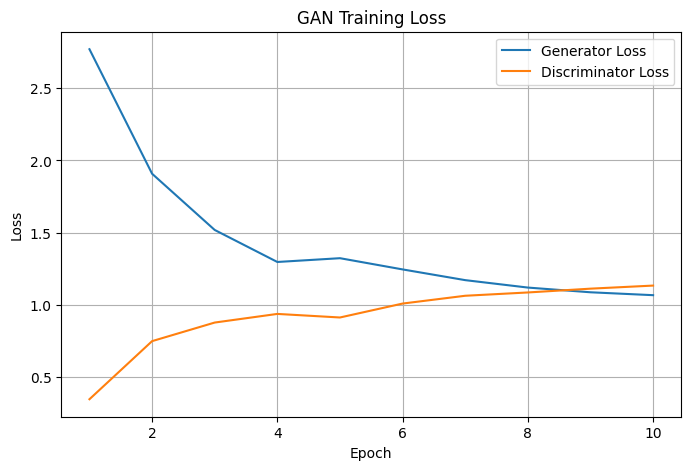

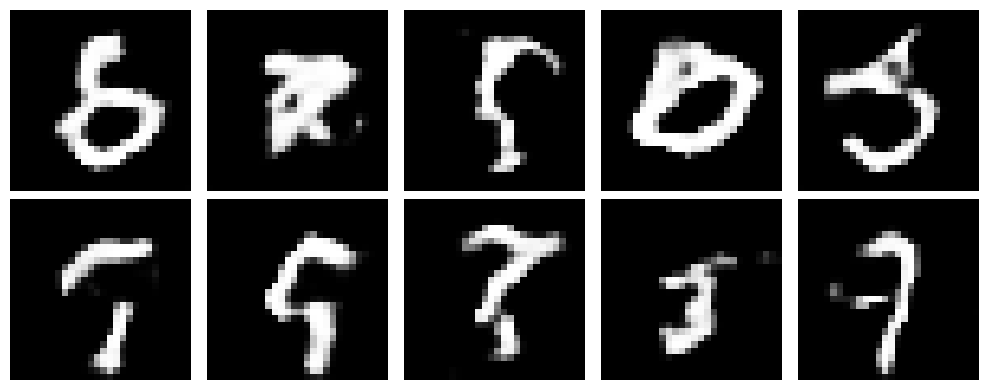

Training completed successfully.
Saved: final_generated_images.png
Saved: gan_training_loss.png
Saved: final_generated_images.npy


In [7]:

# PART D: GAN TRAINING AND SYNTHETIC IMAGE GENERATION
# RITHANYA.G 24BAD132

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("RITHANYA.G 24BAD132")

EPOCHS = 10
LATENT_DIM = 100

cross_entropy = tf.keras.losses.BinaryCrossentropy()

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)
g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

generator_losses = []
discriminator_losses = []

# Training step
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    # Train Discriminator
    noise = tf.random.normal((batch_size, LATENT_DIM))

    with tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)

        real_predictions = discriminator(real_images, training=True)
        fake_predictions = discriminator(
            tf.stop_gradient(fake_images), training=True
        )

        real_loss = cross_entropy(
            tf.ones_like(real_predictions), real_predictions
        )
        fake_loss = cross_entropy(
            tf.zeros_like(fake_predictions), fake_predictions
        )

        d_loss = real_loss + fake_loss

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal((batch_size, LATENT_DIM))

    with tf.GradientTape() as g_tape:
        generated_images = generator(noise, training=True)
        predictions = discriminator(generated_images, training=True)

        g_loss = cross_entropy(
            tf.ones_like(predictions), predictions
        )

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return d_loss, g_loss


# Display generated images
def display_generated_images(epoch):
    noise = tf.random.normal((10, LATENT_DIM))
    images = generator(noise, training=False).numpy()

    plt.figure(figsize=(10, 4))

    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(
            images[i, :, :, 0],
            cmap="gray",
            vmin=-1,
            vmax=1
        )
        plt.axis("off")

    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()


# Train the GAN
for epoch in range(1, EPOCHS + 1):
    d_epoch_losses = []
    g_epoch_losses = []

    for real_images in train_dataset:
        d_loss, g_loss = train_step(real_images)

        d_epoch_losses.append(float(d_loss.numpy()))
        g_epoch_losses.append(float(g_loss.numpy()))

    d_mean = float(np.mean(d_epoch_losses))
    g_mean = float(np.mean(g_epoch_losses))

    discriminator_losses.append(d_mean)
    generator_losses.append(g_mean)

    print(
        f"Epoch {epoch}/{EPOCHS} - "
        f"Discriminator Loss: {d_mean:.4f} - "
        f"Generator Loss: {g_mean:.4f}"
    )

    if epoch == 1 or epoch % 2 == 0:
        display_generated_images(epoch)


# Generate final synthetic images
noise = tf.random.normal((10, LATENT_DIM))
fake_images = generator(noise, training=False).numpy()

# Display real images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        x_train[i, :, :, 0],
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    plt.axis("off")

plt.suptitle("Real MNIST Images")
plt.tight_layout()
plt.show()

# Display synthetic images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        fake_images[i, :, :, 0],
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    plt.axis("off")

plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

# Plot Generator and Discriminator losses
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, EPOCHS + 1),
    generator_losses,
    label="Generator Loss"
)
plt.plot(
    range(1, EPOCHS + 1),
    discriminator_losses,
    label="Discriminator Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.savefig("gan_training_loss.png")
plt.show()

# Save final generated images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        fake_images[i, :, :, 0],
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig("final_generated_images.png", dpi=150)
plt.show()

np.save("final_generated_images.npy", fake_images)

print("Training completed successfully.")
print("Saved: final_generated_images.png")
print("Saved: gan_training_loss.png")
print("Saved: final_generated_images.npy")

In [8]:

# VERIFY SAVED OUTPUTS
# RITHANYA.G 24BAD132

import os

print("RITHANYA.G 24BAD132")

files = [
    "final_generated_images.png",
    "gan_training_loss.png",
    "final_generated_images.npy"
]

for file in files:
    print(file, "->", "Saved" if os.path.exists(file) else "Not found")

RITHANYA.G 24BAD132
final_generated_images.png -> Saved
gan_training_loss.png -> Saved
final_generated_images.npy -> Saved
